# 3 — Train on one date, predict on another

A graph is just data: `train` and `embed` never assume the inference graph is the training one.
This notebook trains on **2018-01-01** and embeds **2019-08-01**, whose network is a different
`Data` object with its own edges.

Two inference inputs are shown:

1. **fully observed** — the new date is complete, so it embeds `num_nodes` rows;
2. **partly observed** — half its locations are withheld through `query_mask`, which is what
   deployment looks like when new locations arrive without features.

Both files are in `examples/era5/data/`.

In [32]:
%matplotlib inline

import sys
from pathlib import Path

import numpy as np
import torch

from nofe import NOFE
from nofe.affinity import affinity_kl_loss

# Resolve paths from the repository layout, not the process cwd: VS Code always starts kernels in
# the workspace folder (`jupyter.notebookFileRoot` is ignored since 2024.4), while `_execute.py`
# runs from this directory. Walk up from the cwd looking for the repo root, so both agree.
REPO = next(
    (
        ancestor
        for ancestor in (Path.cwd(), *Path.cwd().parents)
        if (ancestor / "pyproject.toml").is_file()
    ),
    None,
)
if REPO is None:
    raise RuntimeError(f"run this notebook from inside the nofe checkout, not {Path.cwd()}")
ERA5 = REPO / "examples" / "era5"
DATA = ERA5 / "data"

# The example data is not in Git (21 MB per date), so fail with the fetch command rather than the
# opaque `StopIteration`/`FileNotFoundError` the loader would otherwise raise.
if not (DATA / "2018-01-01.nc").exists():
    raise FileNotFoundError(
        f"missing {DATA / '2018-01-01.nc'}\n"
        "The ERA5 inputs are not committed. Fetch them once with:\n"
        f"  mkdir -p {DATA}\n"
        f"  cp /Volumes/T7-storage/ERA5/data/{{2018-01-01,2019-08-01}}.nc {DATA}/"
    )

# The notebooks import the ERA5 demo and its graph generator straight from the example code, so
# the loader, the graph generator and the globe plot have exactly one implementation in the repo.
# They are imported after `sys.path` is extended, which is why the noqa markers below are needed.
sys.path.insert(0, str(ERA5 / "scripts"))
sys.path.insert(0, str(ERA5 / "utilities"))
sys.path.insert(0, str(REPO / "examples"))
import era5  # noqa: E402
from era5_graph import Era5Graph  # noqa: E402
from graph_utils import knn_indices  # noqa: E402


def kl(on, embedding) -> float:
    """Mean KL between a graph's own feature affinities and an embedding of its rows."""
    return float(affinity_kl_loss(on.x, embedding, on.edge_index, on.num_nodes))


def pca_baseline(data, dims: int = 3) -> torch.Tensor:
    """Best linear projection to ``dims`` dimensions: the reference the model has to beat."""
    centred = data.x - data.x.mean(dim=0, keepdim=True)
    _, _, basis = torch.linalg.svd(centred, full_matrices=False)
    return centred @ basis[:dims].T


def knn_agreement(reference: torch.Tensor, candidate: torch.Tensor, k: int = 10) -> float:
    """Mean share of exact k-nearest neighbours two point sets have in common."""
    ref = reference.detach().cpu().numpy()
    cand = candidate.detach().cpu().numpy()
    ref_nn = knn_indices(ref, k)
    cand_nn = knn_indices(cand, k)
    shared = [len(set(a) & set(b)) / k for a, b in zip(ref_nn, cand_nn, strict=True)]
    return float(np.mean(shared))


def close(a: torch.Tensor, b: torch.Tensor, rtol: float = 1e-4) -> bool:
    """Relative agreement in units of the embedding's own scale."""
    return bool((a - b).abs().max() <= rtol * a.abs().max())


print("nofe ready")


nofe ready


## Load both dates at the same resolution

Same `stride` gives identical lat/lon axes — convenient for plotting, and *not* required for the
transfer to work.

In [ ]:
STRIDE = 4
# Chord on the unit sphere: a 2.5 degree arc, the same neighbourhood as notebook 1.
RADIUS = 0.04363/2
graph = Era5Graph(radius=RADIUS, stride=STRIDE, data_dir=DATA)
train_features, train_latitudes, train_longitudes = graph.load("2018-01-01")
test_features, test_latitudes, test_longitudes = graph.load("2019-08-01")
assert np.array_equal(train_latitudes, test_latitudes)
assert np.array_equal(train_longitudes, test_longitudes)

print(
    "training date nodes:",
    train_features.shape[0] * train_features.shape[1],
    "| new date nodes:",
    test_features.shape[0] * test_features.shape[1],
)


training date nodes: 64440 | new date nodes: 64440


## Train on the first date

Nothing here knows a second date exists.

In [ ]:
NYSTROM = 0.2

CONFIG = {
    "width": 8,
    "ker_width": 32,
    "epochs": 200,
    "seed": 0,
    "early_stopping": True,
    "verbose": True,
    "log_every": 10,
    "nystrom": NYSTROM,
}

train_graph = graph.build(train_features, train_latitudes, train_longitudes)
model = NOFE(dim=3, config=CONFIG)
history = model.train(train_graph)
print(
    f"loss {history[0]['train_loss']:.5f} -> {history[-1]['train_loss']:.6f} "
    f"| mean KL {model.loss(train_graph):.6f}"
)


radius 0.02182 (chord on the unit sphere, 1.25 deg arc), 64440 nodes, 1062000 edges
mean neighbours per receiver: 16.48  max: 215
nodes without a neighbour:    0 (0.00%)
epoch   50/200  train 0.015536  val 0.014500
epoch  100/200  train 0.004329  val 0.004236
epoch  150/200  train 0.004061  val 0.004002
epoch  200/200  train 0.004044  val 0.003942
loss 0.04653 -> 0.004044 | mean KL 0.004032


## Predict on the second date, fully observed

The new graph carries its own `x`, `pos` and edges. The only compatibility requirement is the
widths: 11 input features and `2P + 1 = 7` edge channels, which the generator reproduces for any
point set of the same dimension.

In [35]:
test_graph = graph.build(test_features, test_latitudes, test_longitudes)
built = model.model.config
print(
    "feature width matches:",
    test_graph.x.shape[1] == built["in_channels"],
    "| edge width matches:",
    test_graph.edge_attr.shape[1] == built["edge_channels"],
)

embedding_transfer = model.embed(test_graph)
assert embedding_transfer.shape == (test_graph.num_nodes, 3)
print("embedding on 2019-08-01:", tuple(embedding_transfer.shape))

# The new date is fully observed, so its KL is a real score, not a placeholder.
print(f"mean KL on the new date : {model.loss(test_graph):.6f}")
print(f"PCA-3 KL on the new date: {kl(test_graph, pca_baseline(test_graph, dims=3)):.6f}")


radius 0.02182 (chord on the unit sphere, 1.25 deg arc), 64440 nodes, 1062000 edges
mean neighbours per receiver: 16.48  max: 215
nodes without a neighbour:    0 (0.00%)
feature width matches: True | edge width matches: True
embedding on 2019-08-01: (64440, 3)
mean KL on the new date : 0.005175
PCA-3 KL on the new date: 0.046765


## Compare how each date maps into the shared embedding

The embedding is a *function* of local feature neighbourhoods, so two dates land in the same space:
similar weather regimes get similar colours even though the raw fields differ. The next cell
quantifies that instead of eyeballing it.

In [36]:
train_embedding = model.embed(train_graph)
print(f"KL on the training date: {kl(train_graph, train_embedding):.6f}")
print(f"KL on the new date     : {kl(test_graph, embedding_transfer):.6f}")
assert kl(test_graph, embedding_transfer) < kl(test_graph, pca_baseline(test_graph, dims=3))
print("transfer beats linear PCA on the unseen date: True")


KL on the training date: 0.010200
KL on the new date     : 0.012156
transfer beats linear PCA on the unseen date: True


## Partly observed second date

Withhold half the locations of 2019-08-01 and pass that mask to the generator as `query_mask`.
Their features become the `fill` substitute, they receive messages without sending any, and their
truth — when supplied as `query_features` — goes to `y` for scoring only.

`test_blind` is the honest deployment case: no truth exists for the new locations.

In [37]:
rng = np.random.default_rng(0)
observed_test = rng.random(test_latitudes.size * test_longitudes.size) < 0.5
print(f"observed {observed_test.sum()} of {observed_test.size} locations on the second date")

test_merged = graph.build(
    test_features, test_latitudes, test_longitudes,
    query_mask=~observed_test, query_features=test_features,
)
test_blind = graph.build(
    test_features, test_latitudes, test_longitudes, query_mask=~observed_test
)
print(
    "merged and blind agree on the graph:",
    torch.equal(test_merged.x, test_blind.x)
    and torch.equal(test_merged.edge_index, test_blind.edge_index),
)

predicted = model.embed(test_blind)
print("prediction for all locations:", tuple(predicted.shape))
print(f"mean KL where truth exists   : {model.loss(test_merged):.6f}")


observed 32255 of 64440 locations on the second date
radius 0.02182 (chord on the unit sphere, 1.25 deg arc), 64440 nodes, 532063 edges
mean neighbours per receiver: 8.26  max: 117
nodes without a neighbour:    1811 (2.81%)
radius 0.02182 (chord on the unit sphere, 1.25 deg arc), 64440 nodes, 532063 edges
mean neighbours per receiver: 8.26  max: 117
nodes without a neighbour:    1811 (2.81%)
merged and blind agree on the graph: True
prediction for all locations: (64440, 3)
mean KL where truth exists   : 0.013322


## Two ways to predict the partly observed date

`output_mask` picks which rows come back. Restricting it to the observed rows reproduces a plain
observed-only prediction; leaving it wide returns the withheld locations too. The graph, its edges
and every `x` row are identical in both calls.

In [38]:
# `test_blind` reorders nodes (observed first, then added), and its own `input_mask` marks the
# observed prefix. A mask in grid order would not line up with the graph's rows.
observed_rows = test_blind.clone()
observed_rows.output_mask = test_blind.input_mask
observed_prediction = model.embed(observed_rows)
num_observed_test = int(observed_test.sum())

print("all locations :", tuple(predicted.shape))
print("observed only :", tuple(observed_prediction.shape))
max_diff = (observed_prediction - predicted[:num_observed_test]).abs().max()
print(f"max diff vs the matching prefix: {max_diff:.2e}")
assert close(observed_prediction, predicted[:num_observed_test])
print("observed-only rows are the matching prefix of the full prediction: True")


all locations : (64440, 3)
observed only : (32255, 3)
max diff vs the matching prefix: 1.91e-06
observed-only rows are the matching prefix of the full prediction: True


## Visualise the transfer

Top to bottom: the training date, the new date fully observed, and the new date with half its
locations withheld and predicted.

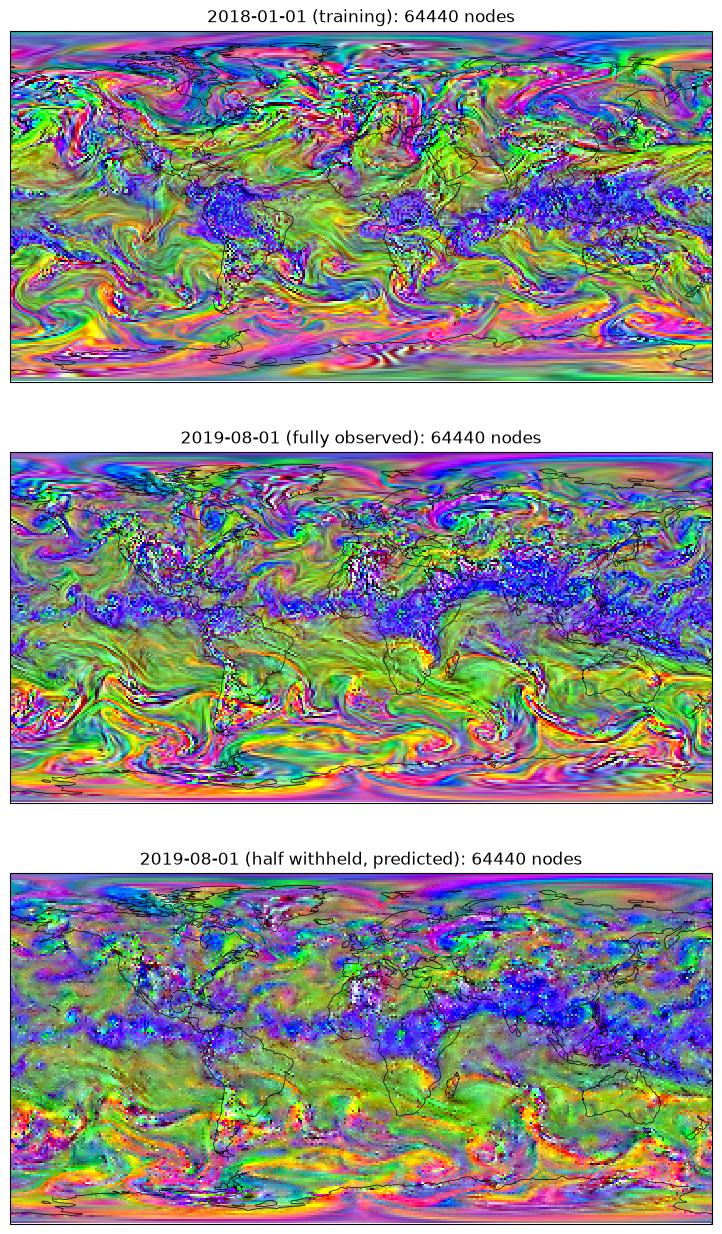

In [39]:
import cartopy.crs as ccrs
import matplotlib.pyplot as plt

# `predicted` is in graph order (known rows first), so it needs the graph-row -> grid-id map
# before it can be drawn; `test_merged.y` is the check that the map points the right way.
row_grid_test = np.empty(test_merged.num_nodes, dtype=np.int64)
row_grid_test[:num_observed_test] = test_merged.observed_index.numpy()
row_grid_test[num_observed_test:] = test_merged.withheld_index.numpy()
predicted_grid = np.full((row_grid_test.size, 3), np.nan, dtype=np.float32)
predicted_grid[row_grid_test] = predicted.numpy()
# A permuted scatter still looks like a globe, so pin it against the truth before reading the map.
test_flat = test_features.reshape(-1, test_features.shape[2])
check = np.full((row_grid_test.size, 3), np.nan, dtype=np.float32)
check[row_grid_test] = test_merged.y[:, :3].numpy()
assert np.allclose(check, test_flat[:, :3], atol=1e-4), "grid scatter is permuted"

panels = [
    ("2018-01-01 (training)", train_embedding.numpy()),
    ("2019-08-01 (fully observed)", embedding_transfer.numpy()),
    ("2019-08-01 (half withheld, predicted)", predicted_grid),
]

# All three panels share one colour scale, computed from the training embedding: without it each
# panel would rescale independently and the same weather regime would get a different colour.
scale = era5.colour_scale(panels[0][1], era5.PERCENTILE)

figure, axes = plt.subplots(
    3, 1, figsize=(12.0, 15.5), subplot_kw={"projection": ccrs.PlateCarree()}
)
for axis, (title, values) in zip(axes, panels, strict=True):
    axis.set_global()
    era5.draw_globe(axis, test_latitudes, test_longitudes, values, scale=scale)
    axis.coastlines(linewidth=0.5)
    axis.set_title(f"{title}: {values.shape[0]} nodes")
plt.show()


## Takeaways

|Fact|Why it matters|
|---|---|
|`train` and `embed` take different `Data`|A graph is data, not state; transfer needs no re-fitting|
|Only the widths must match|`in_channels` = features, `edge_channels` = `2P + 1`|
|`blind` graphs are embed-only|`train`/`loss` refuse scored rows holding substitutes with no `y`|
|`output_mask` chooses the rows|Same graph and inputs; only the returned subset changes|

To adapt to the new date rather than just score it, build a fresh `NOFE` and call `train` on the new
graph; nothing about the objects changes.